In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn as sk
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
dataset7=load_diabetes()
x7=dataset7.data
y9=dataset7.target
print(x7.shape)
print(y9.shape)
print(dataset7.feature_names)

(442, 10)
(442,)
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [ ]:
df_16= pd.DataFrame(x7, columns=dataset7.feature_names)
print(df_16.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [ ]:
df_16["added_column"]=dataset7.target
print(df_16)

          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  added_column  
0   -0.002592  0.019907 -

In [ ]:
f543_col=df_16["bp"]
print(f543_col)

0      0.021872
1     -0.026328
2     -0.005670
3     -0.036656
4      0.021872
         ...   
437    0.059744
438   -0.067642
439    0.017293
440    0.001215
441   -0.081413
Name: bp, Length: 442, dtype: float64


In [ ]:
x_bp=df_16[['bp']]
print(x_bp)

           bp
0    0.021872
1   -0.026328
2   -0.005670
3   -0.036656
4    0.021872
..        ...
437  0.059744
438 -0.067642
439  0.017293
440  0.001215
441 -0.081413

[442 rows x 1 columns]


In [ ]:
x_bp=df_16[['bp']]
y_target=dataset7.target
print(f"x_bmi structure: {x_bp.shape}")
print(f"y_target structure: {y_target.shape}")

x_bmi structure: (442, 1)
y_target structure: (442,)


In [ ]:
train, test, train1, train2= train_test_split(
    x_bp, y_target, test_size=0.3, random_state=42)
print(f"training features size: {train.shape}")
print(f"testing features size:{test.shape}")

training features size: (309, 1)
testing features size:(133, 1)


In [ ]:
k_values=[3,5,7,10]
mean_mse=[]
for k in k_values:
    kf=KFold(n_splits=k, shuffle=True, random_state=42)
    scores = cross_val_score(LinearRegression(), x_bp, y_target, cv=kf,scoring='neg_mean_squared_error')
    mean_mse.append(np.mean(-scores))
    print(f"FOld{k}--> Train rows: {len(train)}| Test rows:{len(test)} | MSE: {mean_mse[-1]:.2f}")

FOld3--> Train rows: 309| Test rows:133 | MSE: 4787.17
FOld5--> Train rows: 309| Test rows:133 | MSE: 4821.39
FOld7--> Train rows: 309| Test rows:133 | MSE: 4825.31
FOld10--> Train rows: 309| Test rows:133 | MSE: 4817.26


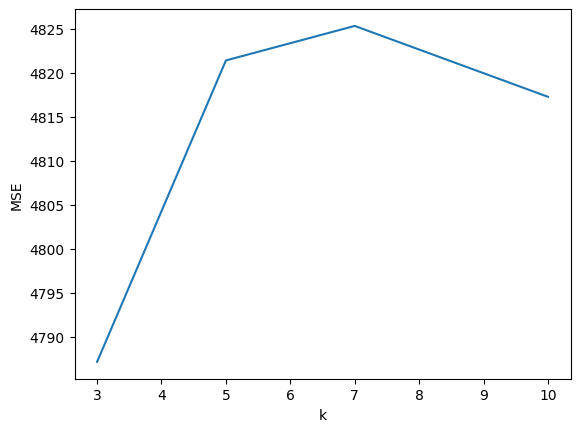

In [ ]:
plt.plot(k_values, mean_mse)
plt.xlabel("k")
plt.ylabel("MSE")
plt.show()

In [ ]:

model=LinearRegression()
model.fit(x_bp, y_target)
print("Model training complete!")
print(f"slope (m): {model.coef_}")
print(f"intercept (c): {model.intercept_:.2f}")

Model training complete!
slope (m): [714.7382595]
intercept (c): 152.13


In [ ]:
model_single= LinearRegression()
model_single.fit(x_bp, y_target)

theta_0=model_single.intercept_
theta_1=model_single.coef_[0]

print("-----simple linear regression")
print(f"theta_0 (intercept):{theta_0:.2f}")
print(f"theta_1 (BMI slope): {theta_1:.4f}")

-----simple linear regression
theta_0 (intercept):152.13
theta_1 (BMI slope): 714.7383


In [ ]:
from sklearn.linear_model import Ridge, Lasso
lr= LinearRegression().fit(x_bp, train1)
ridge=ridge_regression(alpha=1.0).fit(x_bp, train1)
lasso=Lasso(alpha=0.1).fit(x_bp, train1)

ValueError: Found input variables with inconsistent numbers of samples: [442, 309]

In [ ]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso


# 0. CREATE AND TRAIN THE MODELS FIRST
# (Assuming x_bp and y_target are your datasets)
lr = LinearRegression()
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=1.0)

lr.fit(x_bp, y_target)
ridge.fit(x_bp, y_target)
lasso.fit(x_bp, y_target)

# 1. Use each model's .predict method to get predictions for the test data
y_pred_lr = lr.predict(x_bp)
y_pred_ridge = ridge.predict(x_bp)
y_pred_lasso = lasso.predict(x_bp)

# 2. Calculate the Mean Squared Error for all three
mse_lr = mean_squared_error(y_target, y_pred_lr)
mse_ridge = mean_squared_error(y_target, y_pred_ridge)
mse_lasso = mean_squared_error(y_target, y_pred_lasso)

# 3. Compile the calculated errors into a clean, scannable table
mse_table = pd.DataFrame({
    'Model Name': ['Linear Regression (lr)', 'Ridge Regression', 'Lasso Regression'],
    'Test MSE Score': [mse_lr, mse_ridge, mse_lasso]
})

print(mse_table.to_string(index=False, formatters={'Test MSE Score': '{:,.2f}'.format}))


            Model Name Test MSE Score
Linear Regression (lr)       4,774.11
      Ridge Regression       5,063.06
      Lasso Regression       5,216.11
